# 06 Model Evaluation
We evaluate model performance on test data using Accuracy, Precision, Recall, F1-Score, and a Confusion Matrix.

In [2]:
import pandas as pd  # For data loading and manipulation
import joblib  # For loading saved vectorizer, encoder, and model
from scipy.sparse import hstack  # For combining sparse text features with dense metadata
from sklearn.model_selection import train_test_split  # For creating the exact test dataset split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay  # Evaluation metrics and plotting tools
import matplotlib.pyplot as plt  # For rendering the confusion matrix chart

In [3]:
# Load the preprocessed cleaned dataset
df = pd.read_csv('../datasets/cleaned_tickets.csv')

In [4]:
# Handle missing text values safely
df['cleaned_message'] = df['cleaned_message'].fillna('')

In [5]:
# Load fitted TF-IDF vectorizer, One-Hot Encoder, and trained Machine Learning Model
tfidf = joblib.load('../models/tfidf_vectorizer.pkl')
ohe = joblib.load('../models/category_encoder.pkl')
model = joblib.load('../models/priority_classifier_model.pkl')

In [6]:
# Define list of categorical columns used during model training
cat_cols = ['product_area', 'issue_type', 'customer_segment', 'channel', 'platform']

In [7]:
# Transform text and metadata using loaded encoders
X_text = tfidf.transform(df['cleaned_message'])
X_cat = ohe.transform(df[cat_cols])

In [8]:
# Stack text and categorical feature matrices together
X = hstack([X_text, X_cat])
y = df['priority']

In [9]:
# Split data using the exact same random_state (42) to retrieve the test set (20%)
_, X_test, _, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [10]:
# Predict ticket priority levels for the unseen test features
y_pred = model.predict(X_test)

In [15]:
# Print Precision, Recall, F1-Score, and Accuracy across all priority classes
print("--- Classification Report ---")
print(classification_report(y_test, y_pred))

--- Classification Report ---
              precision    recall  f1-score   support

        high       0.20      0.23      0.22      3973
         low       0.39      0.33      0.36      7947
      medium       0.35      0.30      0.33      7063
      urgent       0.05      0.14      0.08      1017

    accuracy                           0.29     20000
   macro avg       0.25      0.25      0.24     20000
weighted avg       0.32      0.29      0.30     20000



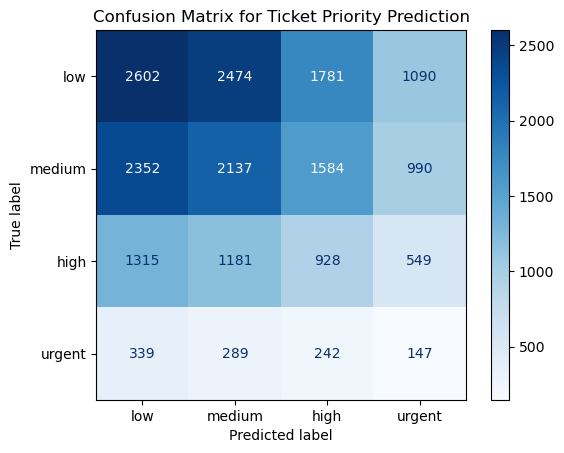

In [12]:
# Define target priority classes in explicit order
labels = ['low', 'medium', 'high', 'urgent']

# Compute matrix showing true vs predicted counts for each priority level
cm = confusion_matrix(y_test, y_pred, labels=labels)

# Display matrix with blue color gradient
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
disp.plot(cmap='Blues')

# Add plot title and show figure
plt.title("Confusion Matrix for Ticket Priority Prediction")
plt.show()